In [1]:
from sklearn.datasets import fetch_openml
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import precision_score, recall_score, precision_recall_curve
from sklearn.base import BaseEstimator
import numpy as np
from sympy.codegen.ast import none




In [2]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [3]:
X, y = mnist['data'], mnist['target']
some_digit = X[0]
some_digit_image = some_digit.reshape(28, 28)
y = y.astype(np.uint8)

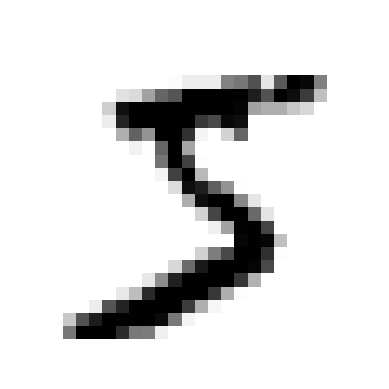

5


In [4]:

plt.imshow(some_digit_image, cmap = "binary")
plt.axis("off")
plt.show()
print(y[0])


In [5]:
X_train, X_test, y_train, y_test = X[: 60000], X[60000:], y[: 60000], y[60000:]
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

In [6]:
SGD = SGDClassifier(random_state = 42)
SGD.fit(X_train, y_train_5)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [7]:
SGD.predict([X[0]])[0]

np.True_

In [8]:
print(cross_val_score(SGD, X_train, y_train_5, cv=3, scoring="accuracy"))


[0.95035 0.96035 0.9604 ]


In [9]:
class Never5Classifier(BaseEstimator):
    def fit(self, X, y = None):
        pass
    def predict(self,X):
        return np.zeros((X.shape[0], 1), dtype = bool)

In [10]:
not_5 = Never5Classifier()
print(cross_val_score(not_5, X_train, y_train_5, cv=3, scoring="accuracy"))

[0.91125 0.90855 0.90915]


In [11]:
y_train_pred = cross_val_predict(SGD, X_train, y_train_5, cv=3)

In [12]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_train_5, y_train_pred))

[[53892   687]
 [ 1891  3530]]


In [13]:
print(precision_score(y_train_5, y_train_pred))
print(recall_score(y_train_5, y_train_pred))

0.8370879772350012
0.6511713705958311


In [14]:
from sklearn.metrics import f1_score
print(f1_score(y_train_5, y_train_pred))

0.7325171197343847


In [15]:
y_score = SGD.decision_function([some_digit])
print(y_score)

[2164.22030239]


In [16]:
threhold = 0
y_some_digit_pred = (y_score > threhold)
print(y_some_digit_pred)
y_scores = cross_val_predict(SGD, X_train, y_train_5, cv = 3, method = "decision_function")
print(y_scores.shape)

[ True]
(60000,)


In [17]:
precision, recall, threshold = precision_recall_curve(y_train_5, y_scores)
print(precision.shape, recall.shape, threshold.shape)

(60001,) (60001,) (60000,)


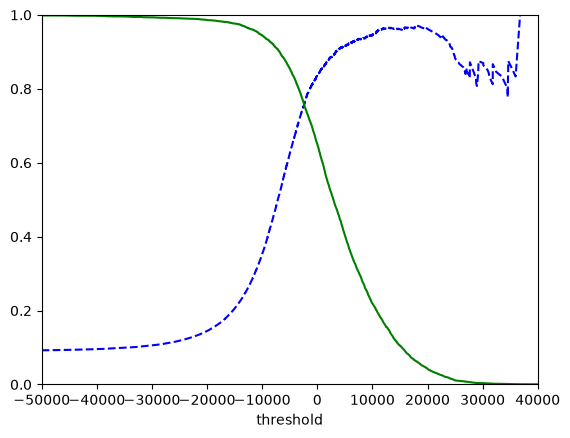

In [18]:
def plot_precision_recall_threshold(precision, recall, threshold):
    plt.plot(threshold, precision[: -1], "b--", label = "Precision")
    plt.plot(threshold, recall[: -1], "g-", label = "Recall")
    plt.ylim(0, 1)
    plt.xlim(-50000, 40000)
    plt.xlabel("threshold")
    plt.show()
plot_precision_recall_threshold(precision, recall, threshold)

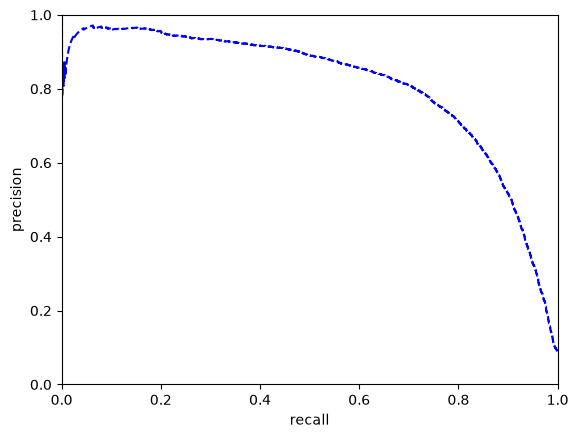

In [19]:
    plt.plot(recall, precision, "b--")
    plt.axis([0, 1, 0, 1])
    plt.xlabel("recall")
    plt.ylabel("precision")
    plt.show()

In [20]:
threshold_90_precision = threshold[np.argmax(precision >= 0.90)]
print(threshold_90_precision)
y_train_pred_90 = (y_scores > threshold_90_precision)
precision_score(y_train_5, y_train_pred_90)
recall_score(y_train_5, y_train_pred_90)

3370.0194991439557


0.47980077476480354

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)
print(fpr.shape, tpr.shape, thresholds.shape)

(3908,) (3908,) (3908,)


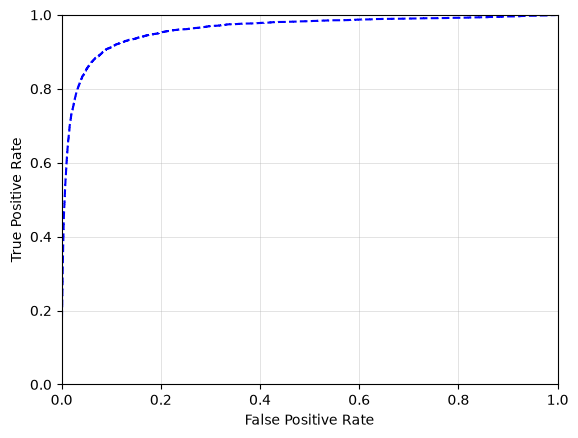

In [22]:
plt.plot(fpr, tpr, "b--", label = "ROC")
plt.axis([0, 1, 0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True)
plt.show()

In [23]:
print(roc_auc_score(y_train_5, y_scores))

0.9604938554008616


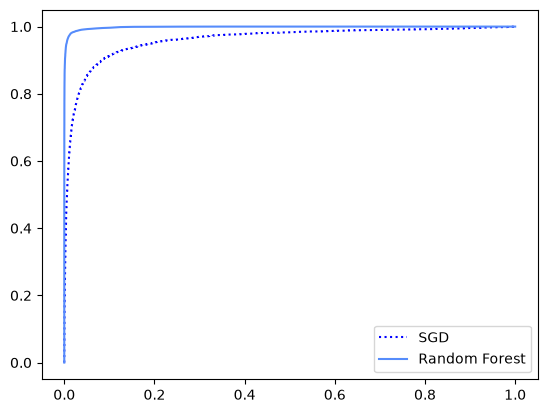

In [24]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)

y_probas_score = cross_val_predict(forest_clf, X_train, y_train_5, cv=3, method = "predict_proba")
y_scores_forest = y_probas_score[:, 1]
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_5,y_scores_forest)
plt.plot(fpr, tpr, "b:", label="SGD")
plt.plot(fpr_forest, tpr_forest, label = "Random Forest")
plt.legend(loc="lower right")
plt.show()

In [25]:
roc_auc_score(y_train_5, y_scores_forest)
precision_score(y_train_5, y_scores_forest >= 0.5)

0.9897468089558485

In [26]:
SGD.fit(X_train, y_train)
SGD.predict([X[0]])

array([3], dtype=uint8)